# 1.Customer Churn Prediction Using Machine Learning

## Project Introduction

Customer churn refers to customers discontinuing their services with a company. In the telecommunications industry, customer churn can negatively impact revenue, profitability, and long-term customer relationships.

This project focuses on analyzing customer behavior and developing machine learning models to predict whether a customer is likely to discontinue telecom services.

The project uses customer demographic information, account details, service subscriptions, and billing information to identify patterns associated with customer churn.

The objective is to develop a reliable classification model that supports customer retention strategies by identifying customers who are at risk of leaving.

## 2.Import Libraries

The required Python libraries are imported to support data manipulation, exploratory data analysis, visualization, and machine learning.

- **Pandas:** Data manipulation and analysis.
- **NumPy:** Numerical computations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical visualization.
- **Scikit-learn:** Data preprocessing, model training, and evaluation.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

## 3.Load Dataset

The Telco Customer Churn dataset is loaded into a Pandas DataFrame for further analysis.

The dataset contains customer demographic information, service subscriptions, account details, billing information, and customer churn status.

In [2]:
df = pd.read_csv("../data/telco_customer_churn.csv")

In [3]:
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (7043, 21)



## 4. Data Understanding

Data understanding is the process of examining the dataset structure, identifying data types, understanding individual features, and analyzing the distribution of the target variable.

This step helps identify the characteristics of the dataset and provides an initial understanding of customer information and churn behavior.


In [4]:
# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Display all column names
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [6]:
# Display column names and their data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
# Generate statistical summary of numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand customer behavior, identify patterns in customer churn, and discover relationships between customer characteristics and churn.

In this stage, we analyze the distribution of churn and investigate how different customer attributes are associated with churn.

The analysis includes:
- Overall churn distribution
- Churn by contract type
- Churn by tenure group
- Churn by payment method
- Churn by internet service
- Churn by online security
- Churn by tech support

In [8]:
# Count customers in each churn category
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
# Calculate percentage distribution of churn
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

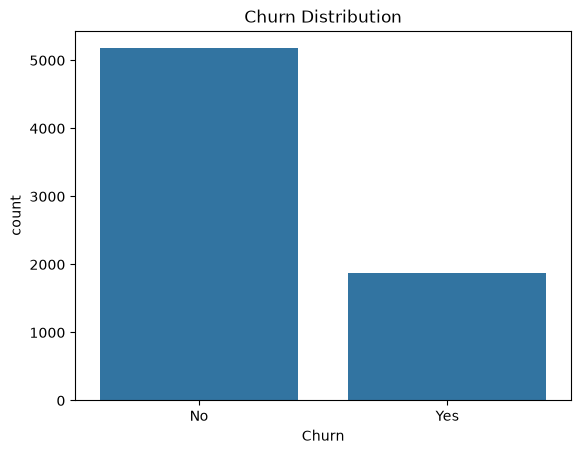

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='Churn')
plt.title('Churn Distribution')
plt.savefig('../visualizations/churn_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [11]:
churn_by_contract = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_contract

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


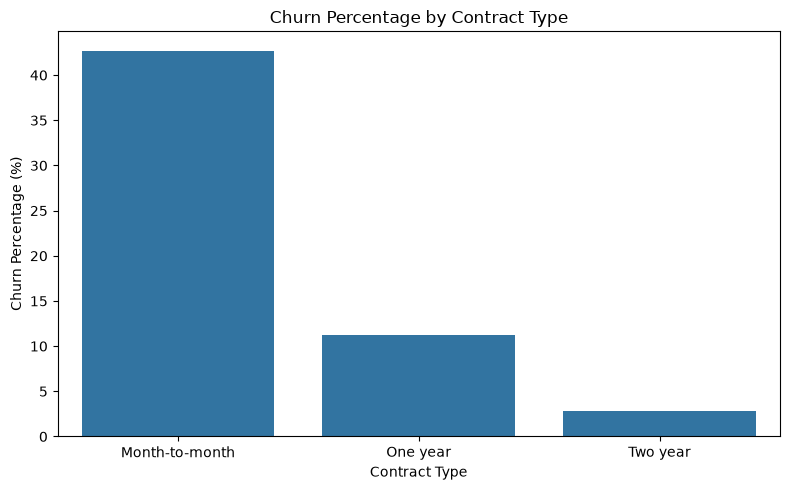

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_contract.reset_index(),
    x='Contract',
    y='Yes'
)

plt.title('Churn Percentage by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Percentage (%)')

plt.tight_layout()

plt.savefig('../visualizations/churn_by_contract.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [13]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [14]:
bins = [0, 12, 24, 48, 60, float('inf')]

labels = [
    '0-12 Months',
    '13-24 Months',
    '25-48 Months',
    '49-60 Months',
    '60+ Months'
]

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels
)

In [15]:
churn_by_tenure = pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_tenure

Churn,No,Yes
TenureGroup,,
0-12 Months,52.321839,47.678161
13-24 Months,71.289062,28.710938
25-48 Months,79.611041,20.388959
49-60 Months,85.576923,14.423077
60+ Months,93.390192,6.609808


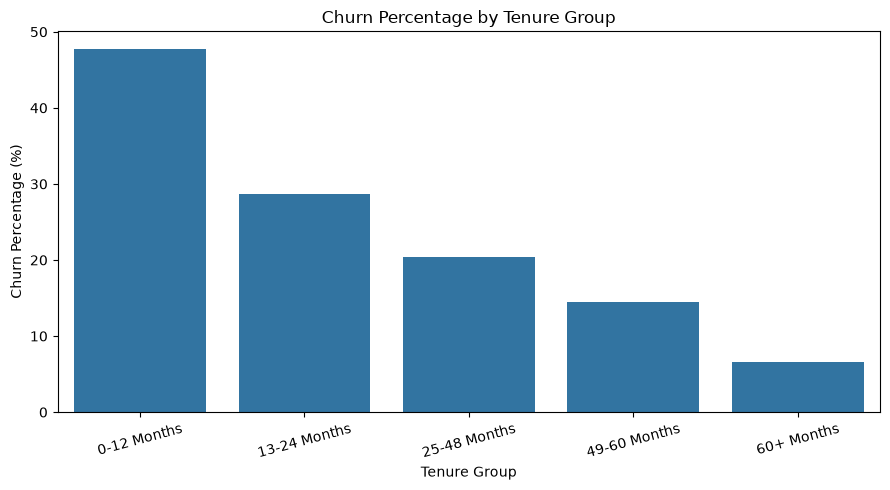

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=churn_by_tenure.reset_index(),
    x='TenureGroup',
    y='Yes'
)

plt.title('Churn Percentage by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Percentage (%)')

plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig('../visualizations/churn_by_tenure.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [17]:
churn_by_payment = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_payment

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


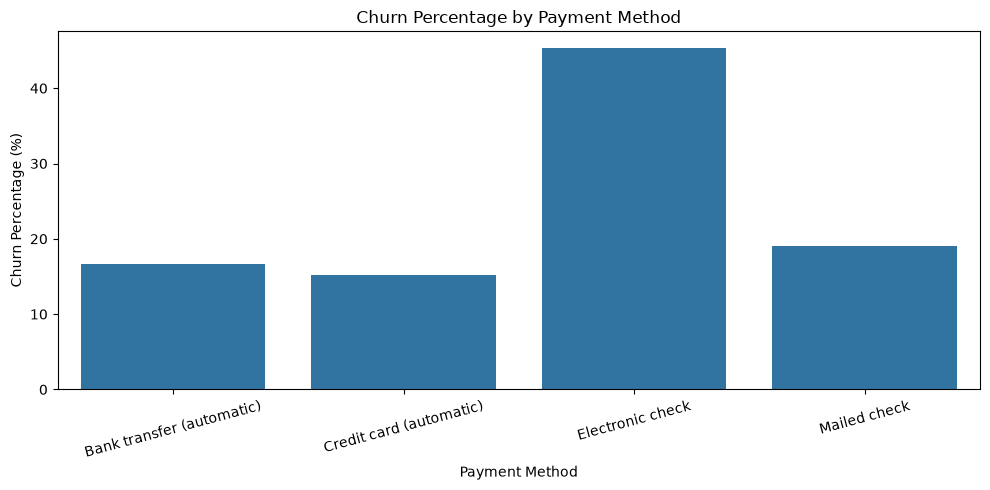

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=churn_by_payment.reset_index(),
    x='PaymentMethod',
    y='Yes'
)

plt.title('Churn Percentage by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Percentage (%)')

plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig('../visualizations/churn_by_payment.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [19]:
churn_by_internet = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_internet

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


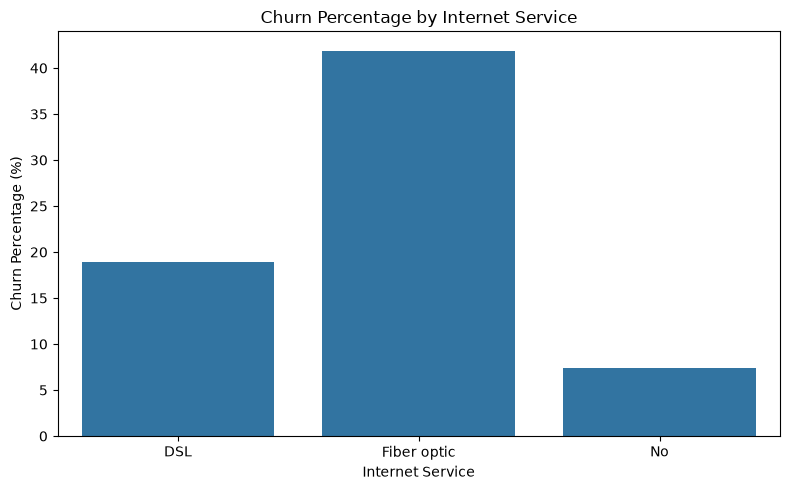

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_internet.reset_index(),
    x='InternetService',
    y='Yes'
)

plt.title('Churn Percentage by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Percentage (%)')

plt.tight_layout()

plt.savefig('../visualizations/churn_by_internet.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [21]:
churn_by_security = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_security

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


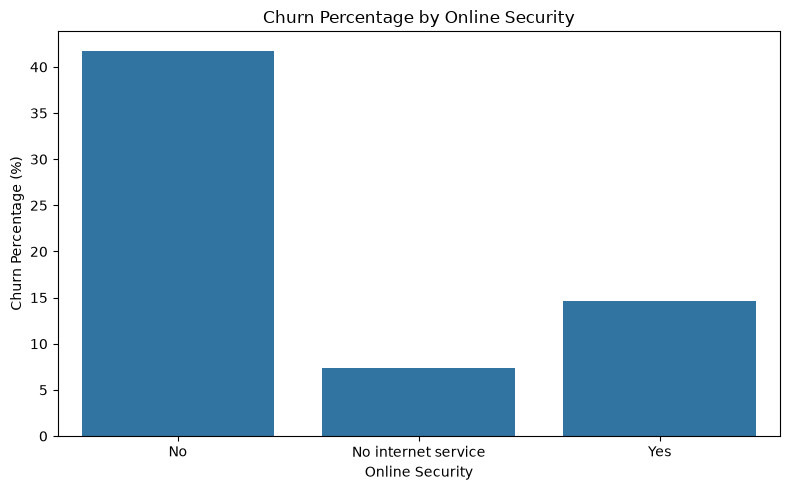

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_security.reset_index(),
    x='OnlineSecurity',
    y='Yes'
)

plt.title('Churn Percentage by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Churn Percentage (%)')

plt.tight_layout()

plt.savefig('../visualizations/churn_by_online_security.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [23]:
churn_by_support = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_support

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


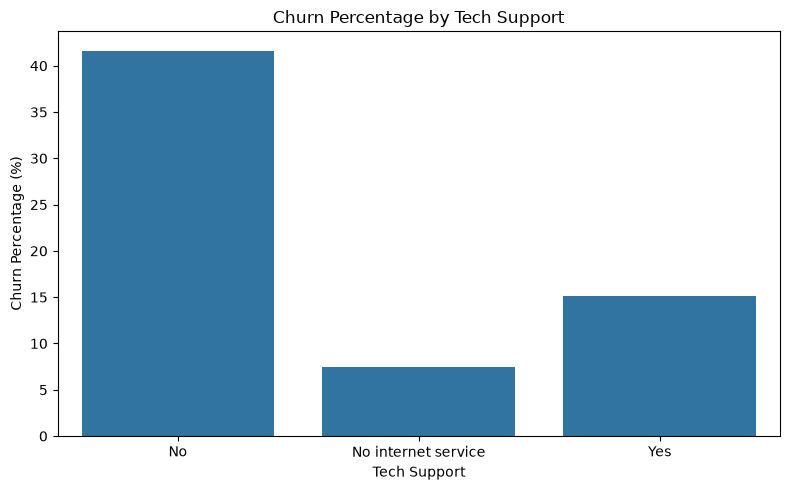

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=churn_by_support.reset_index(),
    x='TechSupport',
    y='Yes'
)

plt.title('Churn Percentage by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Churn Percentage (%)')

plt.tight_layout()

plt.savefig('../visualizations/churn_by_tech_support.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [25]:
churn_by_paperless = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_paperless

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


In [26]:
churn_by_senior = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_senior

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


In [27]:
churn_by_gender = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_gender

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


In [28]:
churn_by_partner = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_partner

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


In [29]:
churn_by_dependents = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_dependents

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


In [30]:
churn_by_multiple = pd.crosstab(
    df['MultipleLines'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_multiple

Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


In [31]:
churn_by_backup = pd.crosstab(
    df['OnlineBackup'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_backup

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


In [32]:
churn_by_device = pd.crosstab(
    df['DeviceProtection'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_device

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


In [33]:
churn_by_streaming_tv = pd.crosstab(
    df['StreamingTV'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_streaming_tv

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


In [34]:
churn_by_streaming_movies = pd.crosstab(
    df['StreamingMovies'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_streaming_movies

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


In [35]:
churn_by_phone = pd.crosstab(
    df['PhoneService'],
    df['Churn'],
    normalize='index'
) * 100

churn_by_phone

Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637


In [36]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


In [37]:
df.groupby('Churn')['TotalCharges'].describe()

,count,unique,top,freq
Churn,,,,
No,5174,4966,,11
Yes,1869,1732,20.2,6


In [38]:
df['TotalCharges'].dtype

<StringDtype(na_value=nan)>

In [39]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [40]:
df.groupby('Churn')['TotalCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5163.0,2555.344141,2329.456984,18.80,577.825,1683.60,4264.125,8672.45
Yes,1869.0,1531.796094,1890.822994,18.85,134.500,703.55,2331.300,8684.80


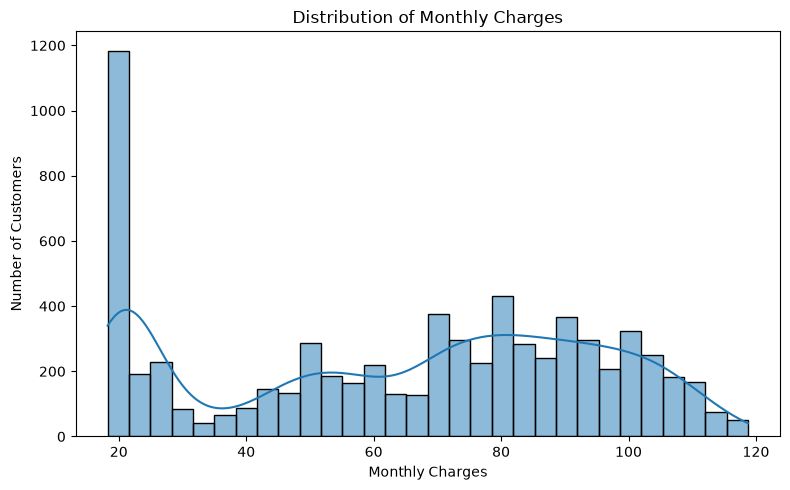

In [41]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True)

plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.tight_layout()

plt.show()

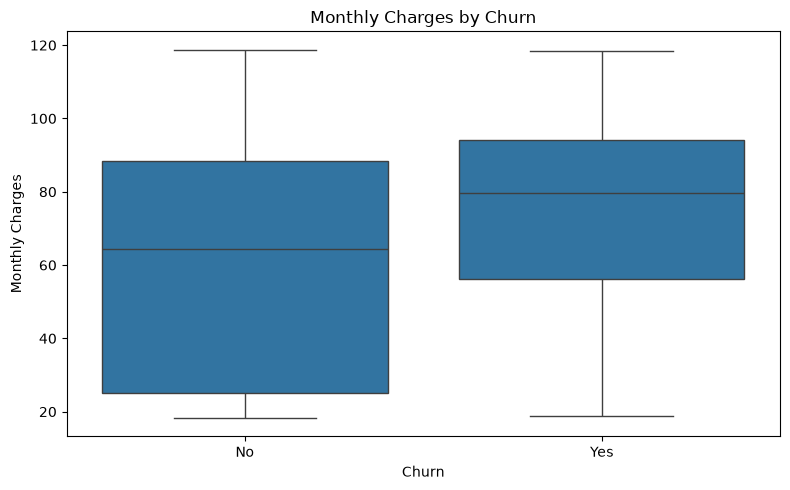

In [42]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges by Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.tight_layout()

plt.show()

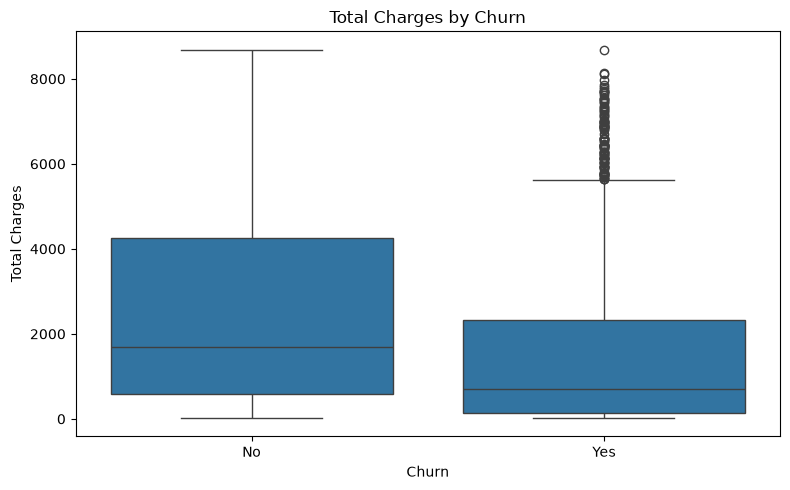

In [43]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='TotalCharges')

plt.title('Total Charges by Churn')
plt.xlabel('Churn')
plt.ylabel('Total Charges')

plt.tight_layout()

plt.show()

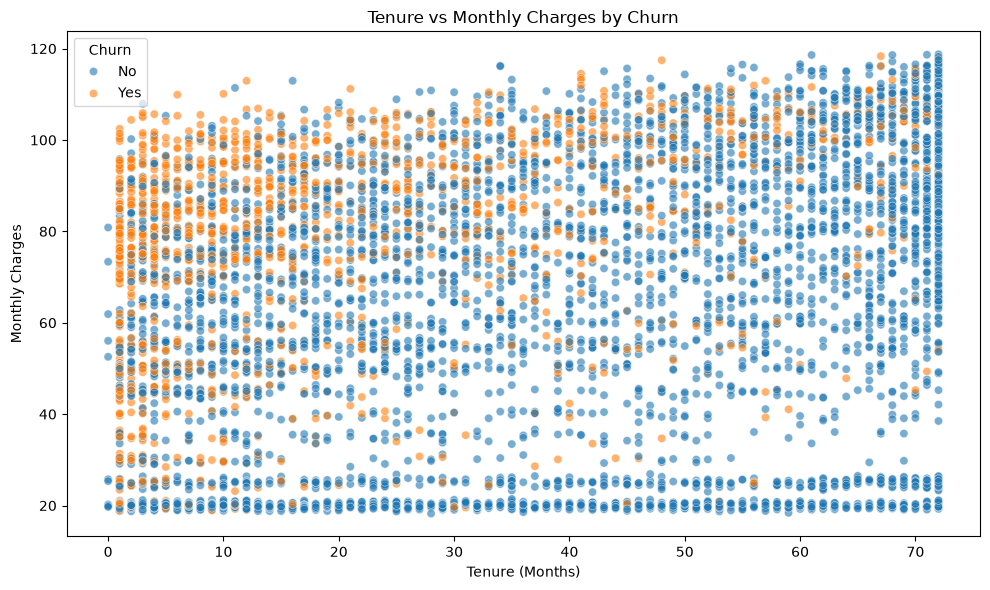

In [44]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='tenure',
    y='MonthlyCharges',
    hue='Churn',
    alpha=0.6
)

plt.title('Tenure vs Monthly Charges by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')

plt.tight_layout()

plt.show()

In [45]:
numerical_df = df.select_dtypes(include='number')

numerical_df.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [46]:
numerical_df.dtypes

SeniorCitizen       int64
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object

In [47]:
correlation_matrix = numerical_df.corr()

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.102411
tenure,0.016567,1.000000,0.247900,0.825880
MonthlyCharges,0.220173,0.247900,1.000000,0.651065
TotalCharges,0.102411,0.825880,0.651065,1.000000


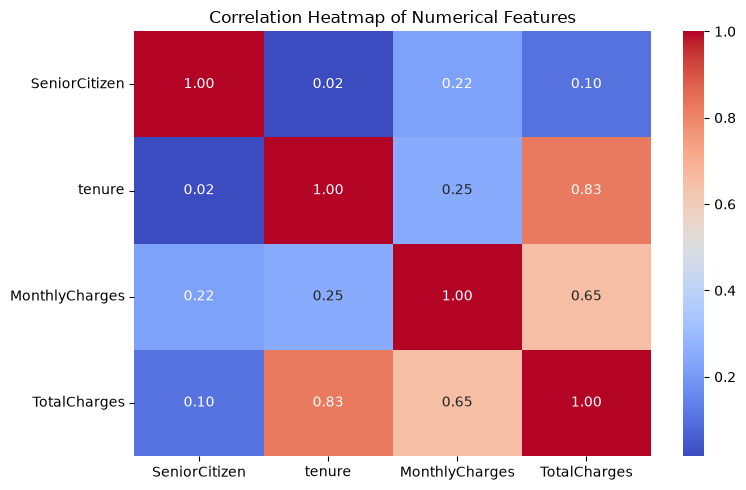

In [48]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Features')

plt.tight_layout()

plt.show()

## 6. Data Cleaning and Preprocessing

Data cleaning and preprocessing are performed to ensure that the dataset is accurate, consistent, and suitable for machine learning.

In this stage, we will:
- Check and handle missing values
- Verify data types
- Check duplicate records
- Handle inconsistent or invalid values
- Prepare the dataset for feature engineering and model building

In [49]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
TenureGroup         11
dtype: int64

In [50]:
df[df['TotalCharges'].isnull()][['tenure', 'TotalCharges', 'TenureGroup']]

,tenure,TotalCharges,TenureGroup
488,0,NaN,NaN
753,0,NaN,NaN
936,0,NaN,NaN
1082,0,NaN,NaN
1340,0,NaN,NaN
3331,0,NaN,NaN
3826,0,NaN,NaN
4380,0,NaN,NaN
5218,0,NaN,NaN
6670,0,NaN,NaN


In [51]:
df = df.dropna(subset=['TotalCharges'])

In [52]:
df.shape

(7032, 22)

In [53]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
TenureGroup         0
dtype: int64

In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
df.dtypes

customerID               str
gender                   str
SeniorCitizen          int64
Partner                  str
Dependents               str
tenure                 int64
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges         float64
Churn                    str
TenureGroup         category
dtype: object

In [56]:
df.shape

(7032, 22)

## 7. Feature Engineering

Feature engineering is the process of creating new features or transforming existing features to improve the usefulness of data for machine learning.

In this stage, we will:
- Create meaningful features from existing columns
- Improve the representation of customer information
- Prepare useful features for model building

In [57]:
df['TenureGroup'].value_counts().sort_index()

TenureGroup
0-12 Months     2175
13-24 Months    1024
25-48 Months    1594
49-60 Months     832
60+ Months      1407
Name: count, dtype: int64

In [58]:
df['AverageMonthlySpend'] = df['TotalCharges'] / df['tenure']

In [59]:
df[['tenure', 'TotalCharges', 'AverageMonthlySpend']].head()

,tenure,TotalCharges,AverageMonthlySpend
0,1,29.85,29.850000
1,34,1889.50,55.573529
2,2,108.15,54.075000
3,45,1840.75,40.905556
4,2,151.65,75.825000


In [60]:
df['AverageMonthlySpend'].describe()

count    7032.000000
mean       64.799424
std        30.185891
min        13.775000
25%        36.179891
50%        70.373239
75%        90.179560
max       121.400000
Name: AverageMonthlySpend, dtype: float64

In [61]:
df.groupby('Churn')['AverageMonthlySpend'].mean()

Churn
No     61.312024
Yes    74.433154
Name: AverageMonthlySpend, dtype: float64

In [62]:
df[['AverageMonthlySpend', 'MonthlyCharges']].corr()

,AverageMonthlySpend,MonthlyCharges
AverageMonthlySpend,1.000000,0.996237
MonthlyCharges,0.996237,1.000000


In [63]:
df.shape

(7032, 23)

In [64]:
df['AverageMonthlySpend'].isnull().sum()

np.int64(0)

## 8. Feature Selection

Feature selection is the process of identifying the most relevant features for machine learning while removing unnecessary or redundant features.

In this stage, we will:
- Identify redundant features
- Analyze relationships between numerical features
- Remove unnecessary columns
- Prepare the final feature set for model training

In [65]:
numerical_features = df.select_dtypes(include='number').columns.tolist()

numerical_features

['SeniorCitizen',
 'tenure',
 'MonthlyCharges',
 'TotalCharges',
 'AverageMonthlySpend']

In [66]:
df[numerical_features].corr()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,AverageMonthlySpend
SeniorCitizen,1.000000,0.015683,0.219874,0.102411,0.217616
tenure,0.015683,1.000000,0.246862,0.825880,0.246198
MonthlyCharges,0.219874,0.246862,1.000000,0.651065,0.996237
TotalCharges,0.102411,0.825880,0.651065,1.000000,0.650915
AverageMonthlySpend,0.217616,0.246198,0.996237,0.650915,1.000000


In [67]:
df.drop(columns=['AverageMonthlySpend'], inplace=True)

In [68]:
df.shape

(7032, 22)

In [69]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn',
 'TenureGroup']

In [70]:
df['Churn'].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [71]:
X = df.drop(columns=['Churn'])
y = df['Churn']

In [72]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7032, 21)
Target shape: (7032,)


In [73]:
X = X.drop(columns=['customerID', 'TenureGroup'])

In [74]:
print("Features shape:", X.shape)
print("Remaining columns:", X.columns.tolist())

Features shape: (7032, 19)
Remaining columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


## 9. Train-Test Split

Train-test split divides the dataset into training and testing subsets.

- Training data is used to train machine learning models.
- Testing data is used to evaluate model performance on unseen data.

We will use an 80:20 split to train and evaluate our models.

In [75]:
from sklearn.model_selection import train_test_split

In [76]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [77]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 19)
X_test: (1407, 19)
y_train: (5625,)
y_test: (1407,)


## 10. Encoding Categorical Variables

Machine learning algorithms generally require numerical inputs. Therefore, categorical variables must be converted into numerical representations.

In this stage, we will:
- Identify categorical and numerical features
- Apply One-Hot Encoding to categorical features
- Preserve numerical features without unnecessary encoding
- Prepare data for model training

In [78]:
categorical_features = X_train.select_dtypes(include=['str', 'object']).columns.tolist()

numerical_features = X_train.select_dtypes(include='number').columns.tolist()

print("Categorical Features:", categorical_features)
print("\nNumerical Features:", numerical_features)

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [79]:
from sklearn.preprocessing import OneHotEncoder

In [80]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [81]:
encoder.fit(X_train[categorical_features])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infreque

In [82]:
X_train_encoded = encoder.transform(X_train[categorical_features])

In [83]:
X_train_encoded.shape

(5625, 41)

In [84]:
encoded_feature_names = encoder.get_feature_names_out(categorical_features)

encoded_feature_names

array(['gender_Female', 'gender_Male', 'Partner_No', 'Partner_Yes',
       'Dependents_No', 'Dependents_Yes', 'PhoneService_No',
       'PhoneService_Yes', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service',
       'TechSupport_Yes', 'StreamingTV_No',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month',
       'Contract_One year', 'Contract_Two year', 'PaperlessBilling_No',
       'PaperlessBilling_Yes', 'Payment

In [85]:
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoded_feature_names,
    index=X_train.index
)

In [86]:
X_train_encoded_df.shape

(5625, 41)

In [87]:
X_test_encoded = encoder.transform(X_test[categorical_features])

In [88]:
X_test_encoded.shape

(1407, 41)

In [89]:
X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoded_feature_names,
    index=X_test.index
)

In [90]:
X_train_numerical = X_train[numerical_features].copy()

X_test_numerical = X_test[numerical_features].copy()

In [91]:
X_train_numerical.shape

(5625, 4)

In [92]:
X_train_preprocessed = pd.concat(
    [X_train_numerical, X_train_encoded_df],
    axis=1
)

X_test_preprocessed = pd.concat(
    [X_test_numerical, X_test_encoded_df],
    axis=1
)

In [93]:
X_train_preprocessed.shape

(5625, 45)

In [94]:
X_test_preprocessed.shape

(1407, 45)

## 11. Feature Scaling

Feature scaling brings numerical features into a comparable range.

In this stage, we will:
- Identify continuous numerical features
- Apply StandardScaler to continuous numerical features
- Fit the scaler only on training data
- Transform both training and testing data
- Preserve binary and One-Hot Encoded features

In [95]:
from sklearn.preprocessing import StandardScaler

In [96]:
continuous_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

In [97]:
scaler = StandardScaler()

In [98]:
scaler.fit(X_train_preprocessed[continuous_features])

StandardScaler()

In [99]:
X_train_preprocessed[continuous_features] = scaler.transform(
    X_train_preprocessed[continuous_features]
)

In [100]:
X_test_preprocessed[continuous_features] = scaler.transform(
    X_test_preprocessed[continuous_features]
)

In [101]:
X_train_preprocessed[continuous_features].describe()

,tenure,MonthlyCharges,TotalCharges
count,5.625000e+03,5.625000e+03,5.625000e+03
mean,-1.291609e-16,3.157968e-17,8.842310e-18
std,1.000089e+00,1.000089e+00,1.000089e+00
min,-1.286145e+00,-1.547843e+00,-1.003365e+00
25%,-9.601500e-01,-9.698847e-01,-8.301191e-01
50%,-1.451620e-01,1.860324e-01,-3.918414e-01
75%,9.550717e-01,8.320837e-01,6.591681e-01
max,1.607062e+00,1.782062e+00,2.805224e+00


In [215]:
import joblib

# Save the fitted OneHotEncoder to reuse categorical encoding during deployment
joblib.dump(encoder, '../models/encoder.pkl')

# Save the fitted StandardScaler to reuse feature scaling during deployment
joblib.dump(scaler, '../models/scaler.pkl')

['../models/scaler.pkl']

## 12. Model Building

In this stage, we will train multiple machine learning algorithms to predict customer churn.

Models:
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier

The models will learn patterns from the training data to predict whether a customer is likely to churn.

In [102]:
from sklearn.linear_model import LogisticRegression

In [103]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [104]:
logistic_model.fit(
    X_train_preprocessed,
    y_train
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [105]:
y_train_pred = logistic_model.predict(X_train_preprocessed)

In [106]:
y_train_pred[:10]

array(['No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'Yes'],
      dtype=object)

In [196]:
y_test_pred= logistic_model.predict(X_test_preprocessed)

In [108]:
y_test_pred[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No'],
      dtype=object)

In [109]:
from sklearn.metrics import accuracy_score

In [110]:
logistic_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

print("Logistic Regression Test Accuracy:", logistic_accuracy)

Logistic Regression Test Accuracy: 0.8045486851457001


In [111]:
from sklearn.metrics import classification_report

In [112]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [113]:
from sklearn.metrics import confusion_matrix

In [114]:
logistic_cm = confusion_matrix(y_test, y_test_pred)

print(logistic_cm)

[[917 116]
 [159 215]]


In [115]:
from sklearn.tree import DecisionTreeClassifier

In [116]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

In [117]:
decision_tree_model.fit(
    X_train_preprocessed,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [118]:
y_test_pred_dt = decision_tree_model.predict(
    X_test_preprocessed
)

In [119]:
y_test_pred_dt[:10]

array(['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No'],
      dtype=object)

In [120]:
decision_tree_accuracy = accuracy_score(
    y_test,
    y_test_pred_dt
)

print("Decision Tree Test Accuracy:", decision_tree_accuracy)

Decision Tree Test Accuracy: 0.7306325515280739


In [121]:
print(classification_report(y_test, y_test_pred_dt))

              precision    recall  f1-score   support

          No       0.82      0.82      0.82      1033
         Yes       0.49      0.50      0.50       374

    accuracy                           0.73      1407
   macro avg       0.66      0.66      0.66      1407
weighted avg       0.73      0.73      0.73      1407



In [122]:
from sklearn.ensemble import RandomForestClassifier

In [123]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [124]:
random_forest_model.fit(
    X_train_preprocessed,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [125]:
y_test_pred_rf = random_forest_model.predict(
    X_test_preprocessed
)

In [126]:
y_test_pred_rf[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No'],
      dtype=object)

In [127]:
random_forest_accuracy = accuracy_score(
    y_test,
    y_test_pred_rf
)

print("Random Forest Test Accuracy:", random_forest_accuracy)

Random Forest Test Accuracy: 0.7874911158493249


In [128]:
print(classification_report(y_test, y_test_pred_rf))

              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1033
         Yes       0.63      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407



In [129]:
from sklearn.metrics import roc_auc_score

In [130]:
y_test_proba_lr = logistic_model.predict_proba(
    X_test_preprocessed
)[:, 1]

In [131]:
logistic_roc_auc = roc_auc_score(
    y_test,
    y_test_proba_lr
)

print("Logistic Regression ROC-AUC:", logistic_roc_auc)

Logistic Regression ROC-AUC: 0.8358928099973599


In [132]:
y_test_proba_rf = random_forest_model.predict_proba(
    X_test_preprocessed
)[:, 1]

In [133]:
random_forest_roc_auc = roc_auc_score(
    y_test,
    y_test_proba_rf
)

print("Random Forest ROC-AUC:", random_forest_roc_auc)

Random Forest ROC-AUC: 0.8136612120867004


In [134]:
y_test_proba_dt = decision_tree_model.predict_proba(
    X_test_preprocessed
)[:, 1]

In [135]:
decision_tree_roc_auc = roc_auc_score(
    y_test,
    y_test_proba_dt
)

print("Decision Tree ROC-AUC:", decision_tree_roc_auc)

Decision Tree ROC-AUC: 0.6564546438129947


In [136]:
from sklearn.metrics import roc_curve

In [137]:
fpr_lr, tpr_lr, thresholds_lr = roc_curve(
    y_test,
    y_test_proba_lr,
    pos_label='Yes'
)

In [138]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(
    y_test,
    y_test_proba_dt,
    pos_label='Yes'
)

In [139]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test,
    y_test_proba_rf,
    pos_label='Yes'
)

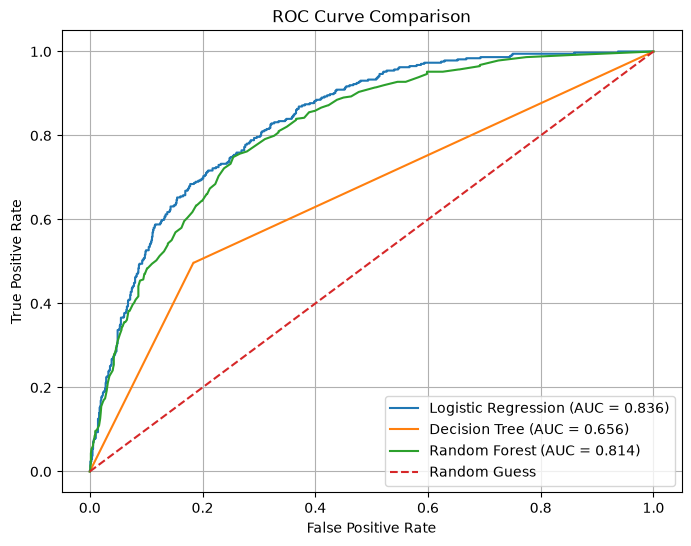

In [140]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {logistic_roc_auc:.3f})')
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {decision_tree_roc_auc:.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {random_forest_roc_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')

plt.legend()
plt.grid()
plt.savefig(
    '../visualizations/roc_curve_comparison.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [141]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        logistic_accuracy,
        decision_tree_accuracy,
        random_forest_accuracy
    ],
    'ROC-AUC': [
        logistic_roc_auc,
        decision_tree_roc_auc,
        random_forest_roc_auc
    ]
})

model_comparison

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.804549,0.835893
1,Decision Tree,0.730633,0.656455
2,Random Forest,0.787491,0.813661


In [142]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_comparison['Churn Precision'] = [
    precision_score(y_test, y_test_pred, pos_label='Yes'),
    precision_score(y_test, y_test_pred_dt, pos_label='Yes'),
    precision_score(y_test, y_test_pred_rf, pos_label='Yes')
]

model_comparison['Churn Recall'] = [
    recall_score(y_test, y_test_pred, pos_label='Yes'),
    recall_score(y_test, y_test_pred_dt, pos_label='Yes'),
    recall_score(y_test, y_test_pred_rf, pos_label='Yes')
]

model_comparison['Churn F1'] = [
    f1_score(y_test, y_test_pred, pos_label='Yes'),
    f1_score(y_test, y_test_pred_dt, pos_label='Yes'),
    f1_score(y_test, y_test_pred_rf, pos_label='Yes')
]

model_comparison

,Model,Accuracy,ROC-AUC,Churn Precision,Churn Recall,Churn F1
0,Logistic Regression,0.804549,0.835893,0.649547,0.574866,0.609929
1,Decision Tree,0.730633,0.656455,0.493369,0.497326,0.495340
2,Random Forest,0.787491,0.813661,0.630662,0.483957,0.547655


In [143]:

model_comparison.to_csv('../reports/model_comparison.csv', index=False)


In [144]:

balanced_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)

balanced_logistic_model.fit(X_train_preprocessed, y_train)

y_test_pred_balanced = balanced_logistic_model.predict(X_test_preprocessed)


In [145]:

balanced_logistic_accuracy = accuracy_score(
    y_test, y_test_pred_balanced
)

print("Balanced Logistic Regression Accuracy:", balanced_logistic_accuracy)

print(classification_report(y_test, y_test_pred_balanced))


Balanced Logistic Regression Accuracy: 0.7249466950959488
              precision    recall  f1-score   support

          No       0.90      0.70      0.79      1033
         Yes       0.49      0.80      0.61       374

    accuracy                           0.72      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.72      0.74      1407



In [146]:

model_comparison.loc[len(model_comparison)] = {
    'Model': 'Balanced Logistic Regression',
    'Accuracy': balanced_logistic_accuracy,
    'ROC-AUC': roc_auc_score(
        y_test,
        balanced_logistic_model.predict_proba(X_test_preprocessed)[:, 1]
    ),
    'Churn Precision': precision_score(
        y_test, y_test_pred_balanced, pos_label='Yes'
    ),
    'Churn Recall': recall_score(
        y_test, y_test_pred_balanced, pos_label='Yes'
    ),
    'Churn F1': f1_score(
        y_test, y_test_pred_balanced, pos_label='Yes'
    )
}

model_comparison


,Model,Accuracy,ROC-AUC,Churn Precision,Churn Recall,Churn F1
0,Logistic Regression,0.804549,0.835893,0.649547,0.574866,0.609929
1,Decision Tree,0.730633,0.656455,0.493369,0.497326,0.495340
2,Random Forest,0.787491,0.813661,0.630662,0.483957,0.547655
3,Balanced Logistic Regression,0.724947,0.835194,0.489327,0.796791,0.606307


In [147]:
model_comparison.to_csv('../reports/model_comparison.csv', index=False)

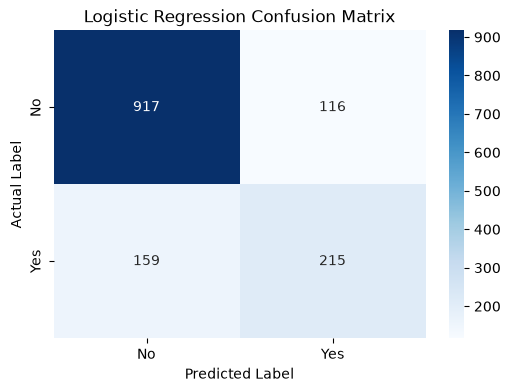

In [149]:

import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_test_pred, labels=['No', 'Yes'])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Logistic Regression Confusion Matrix')
plt.savefig('../visualizations/logistic_confusion_matrix.png',
            dpi=300, bbox_inches='tight')
plt.show()


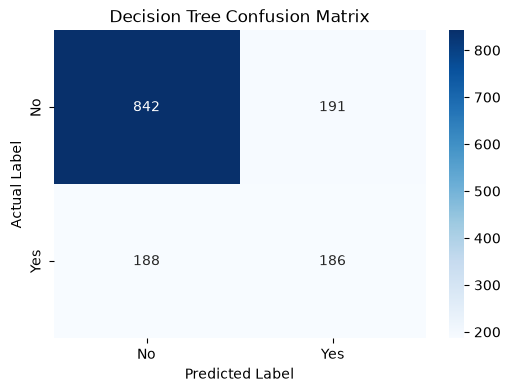

In [150]:

cm_dt = confusion_matrix(
    y_test, y_test_pred_dt, labels=['No', 'Yes']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Decision Tree Confusion Matrix')

plt.savefig(
    '../visualizations/decision_tree_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


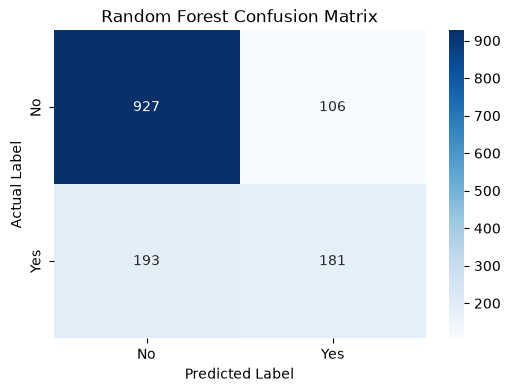

In [151]:

cm_rf = confusion_matrix(
    y_test, y_test_pred_rf, labels=['No', 'Yes']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest Confusion Matrix')

plt.savefig(
    '../visualizations/random_forest_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


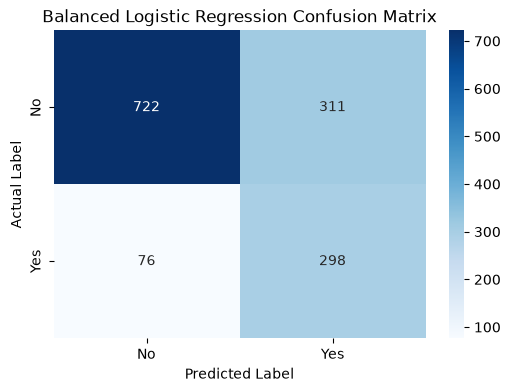

In [152]:

cm_balanced = confusion_matrix(
    y_test, y_test_pred_balanced, labels=['No', 'Yes']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Balanced Logistic Regression Confusion Matrix')

plt.savefig(
    '../visualizations/balanced_logistic_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [153]:

model_comparison.sort_values(
    by='Churn Recall',
    ascending=False
)


,Model,Accuracy,ROC-AUC,Churn Precision,Churn Recall,Churn F1
3,Balanced Logistic Regression,0.724947,0.835194,0.489327,0.796791,0.606307
0,Logistic Regression,0.804549,0.835893,0.649547,0.574866,0.609929
1,Decision Tree,0.730633,0.656455,0.493369,0.497326,0.495340
2,Random Forest,0.787491,0.813661,0.630662,0.483957,0.547655


## 13. Model Evaluation

In this stage, we will evaluate the performance of our trained models using different evaluation metrics and visualizations.

Evaluation techniques:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix
- Precision–Recall Curve

In [154]:

from sklearn.metrics import precision_recall_curve

precision_lr, recall_lr, _ = precision_recall_curve(
    y_test, logistic_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)

precision_dt, recall_dt, _ = precision_recall_curve(
    y_test, decision_tree_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)

precision_rf, recall_rf, _ = precision_recall_curve(
    y_test, random_forest_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)

precision_bal, recall_bal, _ = precision_recall_curve(
    y_test, balanced_logistic_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)


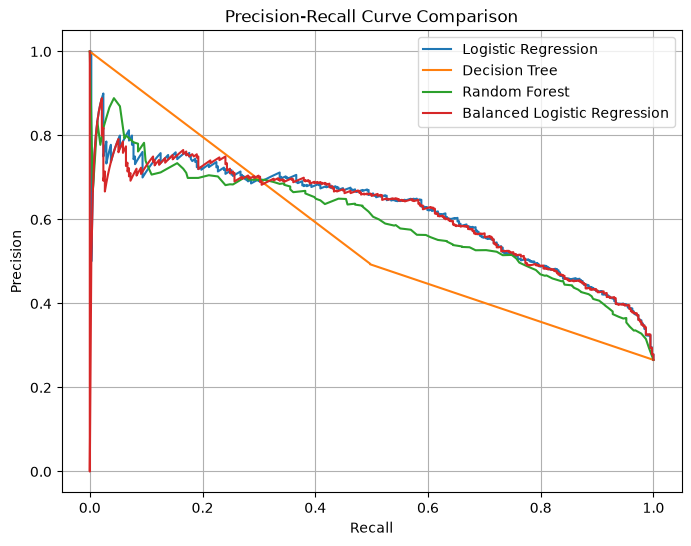

In [155]:

plt.figure(figsize=(8, 6))

plt.plot(recall_lr, precision_lr, label='Logistic Regression')
plt.plot(recall_dt, precision_dt, label='Decision Tree')
plt.plot(recall_rf, precision_rf, label='Random Forest')
plt.plot(recall_bal, precision_bal, label='Balanced Logistic Regression')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')

plt.legend()
plt.grid()

plt.savefig(
    '../visualizations/precision_recall_curve_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [156]:

from sklearn.metrics import average_precision_score

ap_lr = average_precision_score(
    y_test, logistic_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)

ap_dt = average_precision_score(
    y_test, decision_tree_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)

ap_rf = average_precision_score(
    y_test, random_forest_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)

ap_bal = average_precision_score(
    y_test, balanced_logistic_model.predict_proba(X_test_preprocessed)[:, 1],
    pos_label='Yes'
)

print("Logistic Regression AP:", ap_lr)
print("Decision Tree AP:", ap_dt)
print("Random Forest AP:", ap_rf)
print("Balanced Logistic Regression AP:", ap_bal)


Logistic Regression AP: 0.6226047501395225
Decision Tree AP: 0.37963537561449134
Random Forest AP: 0.5942004610222683
Balanced Logistic Regression AP: 0.6183561497489775


In [157]:

model_comparison['Average Precision'] = [
    ap_lr,
    ap_dt,
    ap_rf,
    ap_bal
]

model_comparison


,Model,Accuracy,ROC-AUC,Churn Precision,Churn Recall,Churn F1,Average Precision
0,Logistic Regression,0.804549,0.835893,0.649547,0.574866,0.609929,0.622605
1,Decision Tree,0.730633,0.656455,0.493369,0.497326,0.495340,0.379635
2,Random Forest,0.787491,0.813661,0.630662,0.483957,0.547655,0.594200
3,Balanced Logistic Regression,0.724947,0.835194,0.489327,0.796791,0.606307,0.618356


In [158]:
model_comparison.to_csv('../reports/model_comparison.csv', index=False)

## 14. Model Comparison

In this stage, we will compare the performance of all trained models using their evaluation metrics.

We will:
- Compare Accuracy, ROC-AUC, and Average Precision
- Compare Churn Precision, Recall, and F1-score
- Identify the strengths and weaknesses of each model
- Select a suitable model for hyperparameter tuning

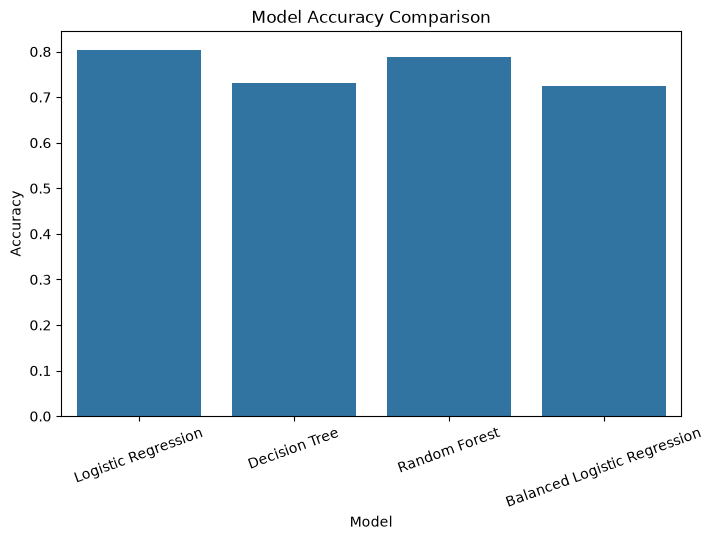

In [159]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy'
)

plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.xticks(rotation=20)

plt.savefig(
    '../visualizations/model_accuracy_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


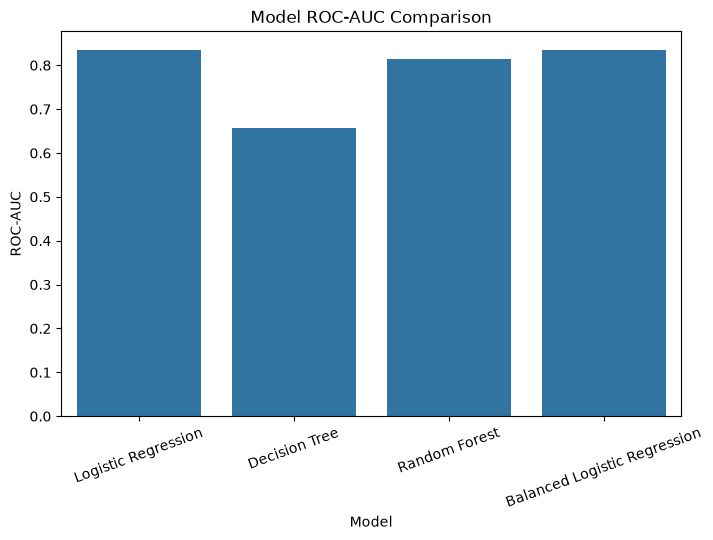

In [160]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='ROC-AUC'
)

plt.title('Model ROC-AUC Comparison')
plt.xlabel('Model')
plt.ylabel('ROC-AUC')
plt.xticks(rotation=20)

plt.savefig(
    '../visualizations/model_roc_auc_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


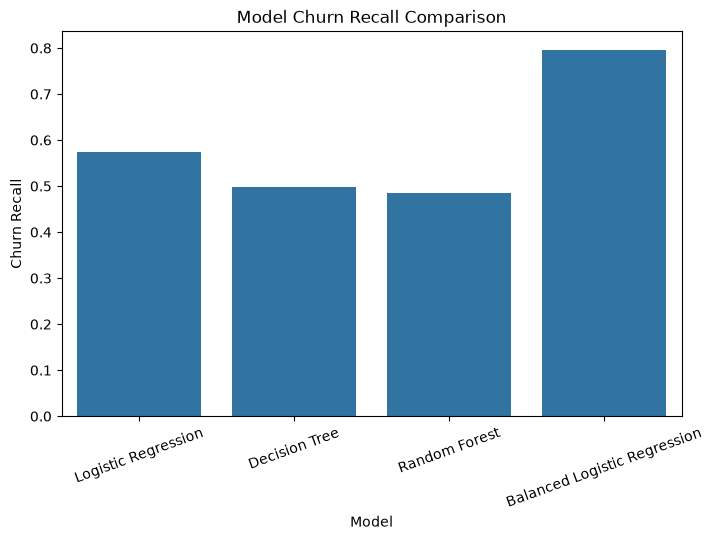

In [161]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Churn Recall'
)

plt.title('Model Churn Recall Comparison')
plt.xlabel('Model')
plt.ylabel('Churn Recall')
plt.xticks(rotation=20)

plt.savefig(
    '../visualizations/model_churn_recall_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


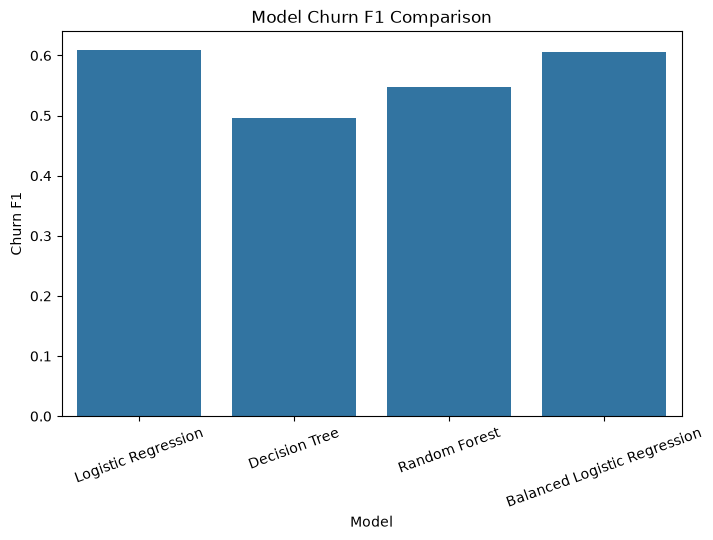

In [162]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Churn F1'
)

plt.title('Model Churn F1 Comparison')
plt.xlabel('Model')
plt.ylabel('Churn F1')
plt.xticks(rotation=20)

plt.savefig(
    '../visualizations/model_churn_f1_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


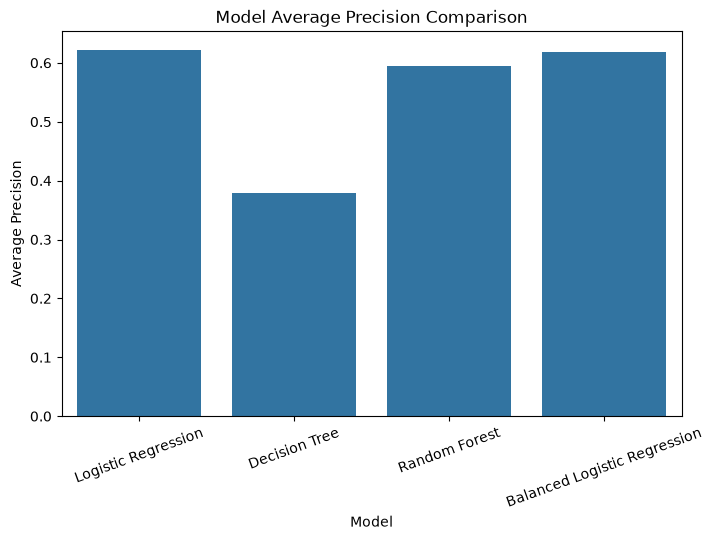

In [163]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Average Precision'
)

plt.title('Model Average Precision Comparison')
plt.xlabel('Model')
plt.ylabel('Average Precision')
plt.xticks(rotation=20)

plt.savefig(
    '../visualizations/model_average_precision_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [164]:

model_comparison.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)


,Model,Accuracy,ROC-AUC,Churn Precision,Churn Recall,Churn F1,Average Precision
0,Logistic Regression,0.804549,0.835893,0.649547,0.574866,0.609929,0.622605
1,Balanced Logistic Regression,0.724947,0.835194,0.489327,0.796791,0.606307,0.618356
2,Random Forest,0.787491,0.813661,0.630662,0.483957,0.547655,0.594200
3,Decision Tree,0.730633,0.656455,0.493369,0.497326,0.495340,0.379635


## 15. Hyperparameter Tuning

Hyperparameter tuning helps improve model performance by finding suitable parameter values.

In this stage, we will:
- Tune Logistic Regression
- Tune Decision Tree
- Tune Random Forest
- Evaluate tuned models
- Compare tuned models with the original models

In [165]:

from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}

logistic_grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=2000, random_state=42),
    param_grid=logistic_param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)


In [166]:

logistic_grid_search.fit(
    X_train_preprocessed,
    y_train
)


Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to d

In [167]:

print("Best Parameters:", logistic_grid_search.best_params_)

print("Best Cross-Validation ROC-AUC:",
      logistic_grid_search.best_score_)


Best Parameters: {'C': 100, 'solver': 'liblinear'}
Best Cross-Validation ROC-AUC: 0.8461995999578903


In [168]:
best_logistic_model = logistic_grid_search.best_estimator_

In [193]:
y_test_pred_best_lr = best_logistic_model.predict(X_test_preprocessed)

In [170]:
best_lr_accuracy = accuracy_score(
    y_test, y_test_pred_best_lr
)

print("Tuned Logistic Regression Accuracy:",
      best_lr_accuracy)

Tuned Logistic Regression Accuracy: 0.7967306325515281


In [171]:
best_lr_roc_auc = roc_auc_score(
    y_test, best_logistic_model.predict_proba(X_test_preprocessed)[:, 1]
)

print("Tuned Logistic Regression ROC-AUC:",
      best_lr_roc_auc)

Tuned Logistic Regression ROC-AUC: 0.8348471043790217


In [172]:
print("Tuned Logistic Regression Classification Report:\n")

print(classification_report(
    y_test, y_test_pred_best_lr
))

Tuned Logistic Regression Classification Report:

              precision    recall  f1-score   support

          No       0.85      0.88      0.86      1033
         Yes       0.63      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



### 15.2 Decision Tree Hyperparameter Tuning

In [173]:
decision_tree_param_grid = {
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5]
}

In [174]:
decision_tree_grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=decision_tree_param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

In [175]:
decision_tree_grid_search.fit(
    X_train_preprocessed,
    y_train
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 5], 'min_samples_split': [2, 10]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_se

In [176]:
print("Best Decision Tree Parameters:",
      decision_tree_grid_search.best_params_)

print("Best Decision Tree Cross-Validation ROC-AUC:",
      decision_tree_grid_search.best_score_)

Best Decision Tree Parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Decision Tree Cross-Validation ROC-AUC: 0.8232376687424587


In [177]:
best_decision_tree_model = decision_tree_grid_search.best_estimator_

In [178]:
y_test_pred_best_dt = best_decision_tree_model.predict(
    X_test_preprocessed
)

In [179]:
best_dt_accuracy = accuracy_score(
    y_test, y_test_pred_best_dt
)

print("Tuned Decision Tree Accuracy:",
      best_dt_accuracy)

Tuned Decision Tree Accuracy: 0.7896233120113717


In [181]:
best_dt_roc_auc = roc_auc_score(
    y_test,
    best_decision_tree_model.predict_proba(X_test_preprocessed)[:, 1]
)

print("Tuned Decision Tree ROC-AUC:",
      best_dt_roc_auc)

Tuned Decision Tree ROC-AUC: 0.8296250472379394


In [182]:
print("Tuned Decision Tree Classification Report:\n")

print(classification_report(
    y_test, y_test_pred_best_dt
))

Tuned Decision Tree Classification Report:

              precision    recall  f1-score   support

          No       0.86      0.85      0.86      1033
         Yes       0.60      0.61      0.61       374

    accuracy                           0.79      1407
   macro avg       0.73      0.73      0.73      1407
weighted avg       0.79      0.79      0.79      1407



### 15.3 Random Forest Hyperparameter Tuning

In [183]:
random_forest_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [184]:
random_forest_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=random_forest_param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

In [185]:
random_forest_grid_search.fit(
    X_train_preprocessed,
    y_train
)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_

In [186]:
print("Best Random Forest Parameters:",
      random_forest_grid_search.best_params_)

print("Best Random Forest Cross-Validation ROC-AUC:",
      random_forest_grid_search.best_score_)

Best Random Forest Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best Random Forest Cross-Validation ROC-AUC: 0.8441892668863928


In [187]:
best_random_forest_model = random_forest_grid_search.best_estimator_

In [188]:
y_test_pred_best_rf = best_random_forest_model.predict(
    X_test_preprocessed
)

In [189]:
best_rf_accuracy = accuracy_score(
    y_test, y_test_pred_best_rf
)

print("Tuned Random Forest Accuracy:",
      best_rf_accuracy)

Tuned Random Forest Accuracy: 0.7938877043354655


In [190]:
best_rf_roc_auc = roc_auc_score(
    y_test,
    best_random_forest_model.predict_proba(X_test_preprocessed)[:, 1]
)

print("Tuned Random Forest ROC-AUC:",
      best_rf_roc_auc)

Tuned Random Forest ROC-AUC: 0.8329731170827921


In [191]:
print("Tuned Random Forest Classification Report:\n")

print(classification_report(
    y_test, y_test_pred_best_rf
))

Tuned Random Forest Classification Report:

              precision    recall  f1-score   support

          No       0.84      0.89      0.86      1033
         Yes       0.64      0.53      0.58       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



In [200]:
tuning_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Tuned Logistic Regression',
        'Decision Tree',
        'Tuned Decision Tree',
        'Random Forest',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        logistic_accuracy,
        best_lr_accuracy,
        decision_tree_accuracy,
        best_dt_accuracy,
        random_forest_accuracy,
        best_rf_accuracy
    ],
    'ROC-AUC': [
        logistic_roc_auc,
        best_lr_roc_auc,
        decision_tree_roc_auc,
        best_dt_roc_auc,
        random_forest_roc_auc,
        best_rf_roc_auc
    ]
})

tuning_comparison = tuning_comparison.sort_values(
    by='ROC-AUC', ascending=False
)

tuning_comparison

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.804549,0.835893
1,Tuned Logistic Regression,0.796731,0.834847
5,Tuned Random Forest,0.793888,0.832973
3,Tuned Decision Tree,0.789623,0.829625
4,Random Forest,0.787491,0.813661
2,Decision Tree,0.730633,0.656455


### 15.4 Hyperparameter Tuning Comparison

The following table compares the performance of the original models
with their tuned versions using Accuracy and ROC-AUC.

| Model | Accuracy | ROC-AUC |
|---|---:|---:|
| Logistic Regression | 80.45% | 83.59% |
| Tuned Logistic Regression | 79.67% | 83.48% |
| Tuned Random Forest | 79.39% | 83.30% |
| Tuned Decision Tree | 78.96% | 82.96% |
| Random Forest | 78.75% | 81.37% |
| Decision Tree | 73.06% | 65.65% |

**Observation:**

Original Logistic Regression achieved the highest Accuracy and ROC-AUC.
Hyperparameter tuning significantly improved Decision Tree and
moderately improved Random Forest performance.
However, tuning Logistic Regression did not improve its test performance.

In [202]:
tuning_comparison.to_csv(
    '../reports/hyperparameter_tuning_comparison.csv',
    index=False
)

## 16. Final Model Selection

In this section, we select the final machine learning model based on its performance and business objectives.

The selection criteria include:
- Accuracy
- ROC-AUC
- Churn Precision
- Churn Recall
- Churn F1-Score

The selected model should provide a good balance between overall predictive performance and identifying customers who are likely to churn.

In [206]:

import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score

# Create model comparison DataFrame
model_comparison = pd.DataFrame([
    {
        'Model': 'Logistic Regression',
        'Accuracy': logistic_accuracy,
        'ROC-AUC': logistic_roc_auc,
        'Churn Precision': precision_score(y_test, y_test_pred, pos_label='Yes'),
        'Churn Recall': recall_score(y_test, y_test_pred, pos_label='Yes'),
        'Churn F1': f1_score(y_test, y_test_pred, pos_label='Yes')
    },
    {
        'Model': 'Decision Tree',
        'Accuracy': decision_tree_accuracy,
        'ROC-AUC': decision_tree_roc_auc,
        'Churn Precision': precision_score(y_test, y_test_pred_dt, pos_label='Yes'),
        'Churn Recall': recall_score(y_test, y_test_pred_dt, pos_label='Yes'),
        'Churn F1': f1_score(y_test, y_test_pred_dt, pos_label='Yes')
    },
    {
        'Model': 'Random Forest',
        'Accuracy': random_forest_accuracy,
        'ROC-AUC': random_forest_roc_auc,
        'Churn Precision': precision_score(y_test, y_test_pred_rf, pos_label='Yes'),
        'Churn Recall': recall_score(y_test, y_test_pred_rf, pos_label='Yes'),
        'Churn F1': f1_score(y_test, y_test_pred_rf, pos_label='Yes')
    }
])

# Add Balanced Logistic Regression
model_comparison.loc[len(model_comparison)] = {
    'Model': 'Balanced Logistic Regression',
    'Accuracy': balanced_logistic_accuracy,
    'ROC-AUC': roc_auc_score(
        y_test,
        balanced_logistic_model.predict_proba(X_test_preprocessed)[:, 1]
    ),
    'Churn Precision': precision_score(
        y_test, y_test_pred_balanced, pos_label='Yes'
    ),
    'Churn Recall': recall_score(
        y_test, y_test_pred_balanced, pos_label='Yes'
    ),
    'Churn F1': f1_score(
        y_test, y_test_pred_balanced, pos_label='Yes'
    )
}

# Display comparison
model_comparison


,Model,Accuracy,ROC-AUC,Churn Precision,Churn Recall,Churn F1
0,Logistic Regression,0.804549,0.835893,0.649547,0.574866,0.609929
1,Decision Tree,0.730633,0.656455,0.493369,0.497326,0.495340
2,Random Forest,0.787491,0.813661,0.630662,0.483957,0.547655
3,Balanced Logistic Regression,0.724947,0.835194,0.489327,0.796791,0.606307


## 17. Model Saving

In this section, we save the selected Logistic Regression model using Joblib.
The saved model can be reused later for predictions without retraining.

In [207]:
import joblib

joblib.dump(logistic_model, '../models/best_churn_model.pkl')

['../models/best_churn_model.pkl']


## 18. Streamlit Deployment

In this section, we deploy the selected Logistic Regression model using Streamlit.
The application allows users to enter customer information and predict the likelihood of customer churn.

The deployment includes:
- Customer information input form
- Churn prediction and probability
- Customer retention recommendations
- Prediction history
- Customer analytics dashboard
- Model performance information
